# KO1 — Somatic Mutations Show Higher AlphaMissense Pathogenicity Scores Than Germline Mutations

## Overview

This notebook tests **Key Objective 1**: that somatic mutations in PDAC patients carry higher AlphaMissense (AM) pathogenicity scores than germline mutations in healthy individuals. It compares AM score distributions between TCGA-PAAD (somatic) and 1000 Genomes (germline) mutations using descriptive statistics, a one-sided Mann-Whitney U test with the Common Language Effect Size (CLES), and a gene-level pathogenicity breakdown by median AM score. The notebook produces two figures — an AM score distribution plot and a stacked bar chart of pathogenic gene shares — that are exported for use in the final report.

## Data

**Input**
- `../Data/merged_tcga_1000G.parquet` — merged table of somatic (TCGA-PAAD, `source == 'TCGA'`) and germline (1000 Genomes, `source == '1000G'`) mutations.
  Columns used: `source`, `gene_name`, `sample_id`, `am_pathogenicity`, `chrom`, `pos`, `ref`, `alt`.

**Processing**
- Split the merged table into `tcga` (somatic, 168 patients) and `g1000` (germline, 3,202 individuals) by `source`.
- Drop nulls in `am_pathogenicity` before computing statistics or categorising.
- Categorise individual mutations, and genes by their **median** AM score, into *benign* / *uncertain* / *pathogenic* using the AlphaMissense thresholds `AM_BENIGN_MAX = 0.34` and `AM_PATH_MIN = 0.564`.

**Output**
- `../Figures/KO1_am_score_distribution.png` / `.pdf` / `.svg` — Figure 1 (AM score distribution)
- `../Figures/KO1_pathogenic_gene_share.png` / `.pdf` / `.svg` — Figure 2 (pathogenic gene share)

## Method

- **Descriptive statistics**: median / mean / std AM score and the share of benign / uncertain / pathogenic mutations per group.
- **Mann-Whitney U test** (`scipy.stats.mannwhitneyu`, one-sided, H₁: PDAC > Healthy) with the **Common Language Effect Size**, `CLES = U / (n_PDAC × n_Healthy)` — the probability that a randomly drawn somatic mutation has a higher AM score than a randomly drawn germline mutation.
- **Gene-level categorisation**: each gene is assigned the **median** AM score of its mutations (per dataset), then classified with the same AlphaMissense thresholds.
- **Visualisation**: histogram + KDE distribution plot (`plot_distribution`) and horizontal stacked bar chart (`plot_stacked_bar`), both adapted from `03_validation_RQ12.ipynb`.

## Content

| # | Name | Description |
|---|------|-------------|
| 1 | Setup & Data Loading | Imports, plotting style, AM thresholds/colour constants, load `merged_tcga_1000G.parquet`, split into PDAC (somatic) and Healthy (germline), set up the figure output directory |
| 2 | Descriptive Statistics | Median / mean / std AM scores and pathogenicity shares per group — reproduces somatic median ≈ 0.2239 vs germline median ≈ 0.0763 |
| 3 | Statistical Test — Mann-Whitney U & CLES | One-sided Mann-Whitney U test and Common Language Effect Size (CLES ≈ 0.829), with interpretation |
| 4 | Figure 1 — AM Score Distribution | Histogram + KDE of AM scores, somatic vs germline; saved as `KO1_am_score_distribution.{png,pdf}` |
| 5 | Figure 2 — Pathogenic Gene Share | Stacked bar chart of benign / uncertain / pathogenic gene shares by gene-median AM score; saved as `KO1_pathogenic_gene_share.{png,pdf}` |

## 1. Setup & Data Loading

In [15]:
import pathlib
import polars as pl
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [16]:
sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 130})

In [17]:
COLOR_PDAC      = '#E69F00'   # orange    — TCGA / PDAC  (Wong palette)
COLOR_HEALTHY   = '#56B4E9'   # sky-blue  — 1000G / Healthy
COLOR_BENIGN    = '#2065ab'   # RdBu_r 0.10 — benign
COLOR_UNCERTAIN = '#b1d5e7'   # RdBu_r 0.35 — uncertain
COLOR_PATH      = '#b1182b'   # RdBu_r 0.90 — pathogenic

AM_BENIGN_MAX = 0.34    # AlphaMissense: AM <= 0.34  -> benign
AM_PATH_MIN   = 0.564   # AlphaMissense: AM >= 0.564 -> pathogenic

# DATA_PATH = 'C:/2604_BRP/Data/merged_tcga_1000G.parquet'   # coworker path
DATA_PATH = 'C:/Users/daane/Desktop/DATA/merged_tcga_1000G.parquet'

In [18]:
df = (
    pl.read_parquet(DATA_PATH)
    .select(['source', 'gene_name', 'sample_id', 'am_pathogenicity',
             'chrom', 'pos', 'ref', 'alt'])
)
tcga  = df.filter(pl.col('source') == 'TCGA')
g1000 = df.filter(pl.col('source') == '1000G')

print(f'TCGA rows : {len(tcga):,}')
print(f'1000G rows: {len(g1000):,}')

out_dir = pathlib.Path('../Figures')
out_dir.mkdir(exist_ok=True)

TCGA rows : 15,695
1000G rows: 32,063,253


## 2. Descriptive Statistics

In [19]:
def _cat_expr():
    return (
        pl.when(pl.col('am_pathogenicity') <= AM_BENIGN_MAX).then(pl.lit('benign'))
        .when(pl.col('am_pathogenicity') >= AM_PATH_MIN).then(pl.lit('pathogenic'))
        .otherwise(pl.lit('uncertain'))
        .alias('category')
    )


def _tally(result):
    c = {'benign': 0, 'uncertain': 0, 'pathogenic': 0}
    for row in result.iter_rows(named=True):
        c[row['category']] = int(row['count'])
    return c


def categorize_mutations(subset):
    subset = subset.filter(pl.col('am_pathogenicity').is_not_null())
    return _tally(
        subset
        .with_columns(_cat_expr())
        .group_by('category')
        .agg(pl.len().alias('count'))
    )


def stats_table(subset, label):
    s    = subset['am_pathogenicity']
    cats = categorize_mutations(subset)
    n_am = cats['benign'] + cats['uncertain'] + cats['pathogenic']
    def pct(n): return round(100 * n / n_am, 1) if n_am > 0 else 0.0
    return dict(
        Group          = label,
        n_mutations    = len(subset),
        n_variants     = subset.select(['chrom', 'pos', 'ref', 'alt']).unique().height,
        n_individuals  = subset['sample_id'].n_unique(),
        mean           = round(float(s.mean()),   4),
        median         = round(float(s.median()), 4),
        std            = round(float(s.std()),    4),
        n_benign       = cats['benign'],
        pct_benign     = pct(cats['benign']),
        n_uncertain    = cats['uncertain'],
        pct_uncertain  = pct(cats['uncertain']),
        n_pathogenic   = cats['pathogenic'],
        pct_pathogenic = pct(cats['pathogenic']),
    )

In [20]:
pl.Config.set_tbl_rows(-1)
pl.DataFrame([
    stats_table(tcga,  'PDAC — somatic'),
    stats_table(g1000, 'Healthy — germline'),
])

Group,n_mutations,n_variants,n_individuals,mean,median,std,n_benign,pct_benign,n_uncertain,pct_uncertain,n_pathogenic,pct_pathogenic
str,i64,i64,i64,f64,f64,f64,i64,f64,i64,f64,i64,f64
"""PDAC — somatic""",15695,15559,168,0.3891,0.2239,0.3347,9305,59.3,1701,10.8,4689,29.9
"""Healthy — germline""",32063253,330695,3202,0.1134,0.0763,0.1198,30582733,95.4,831555,2.6,648965,2.0


## 3. Statistical Test — Mann-Whitney U & CLES

Mann-Whitney U test on the full population (all somatic vs all germline mutations).
- **H₁**: PDAC AM scores are stochastically greater than Healthy AM scores (one-sided)
- **Effect size**: CLES = U / (n\_PDAC × n\_Healthy) — probability that a random PDAC mutation has a higher AM score than a random Healthy mutation
- **Note**: with n\_Healthy ≈ 32 million, the p-value is essentially always < 0.001; CLES is the informative effect-size metric

In [21]:
from scipy.stats import mannwhitneyu
from IPython.display import display

p_am = tcga['am_pathogenicity'].drop_nulls().to_numpy()
h_am = g1000['am_pathogenicity'].drop_nulls().to_numpy()
n_p, n_h = len(p_am), len(h_am)

print(f'Computing Mann-Whitney U: {n_p:,} PDAC vs {n_h:,} Healthy mutations ...')
U, pval = mannwhitneyu(p_am, h_am, alternative='greater')
cles = U / (n_p * n_h)

pl.Config.set_tbl_rows(-1)
display(pl.DataFrame({
    'Metric': [
        'n PDAC (with AM score)',
        'n Healthy (with AM score)',
        'Mann-Whitney U',
        'p-value  (H₁: PDAC > Healthy, one-sided)',
        'CLES  (P[PDAC score > Healthy score])',
    ],
    'Value': [
        f'{n_p:,}',
        f'{n_h:,}',
        f'{U:,.0f}',
        f'{pval:.2e}',
        f'{cles:.4f}',
    ],
}))
print(f'\nInterpretation: CLES = {cles:.4f} — in {cles*100:.1f}% of all PDAC–Healthy '
      f'mutation pairs, the PDAC mutation has a higher AM score than the Healthy mutation.')

Computing Mann-Whitney U: 15,695 PDAC vs 32,063,253 Healthy mutations ...


Metric,Value
str,str
"""n PDAC (with AM score)""","""15,695"""
"""n Healthy (with AM score)""","""32,063,253"""
"""Mann-Whitney U""","""417,595,239,590"""
"""p-value (H₁: PDAC > Healthy, …","""0.00e+00"""
"""CLES (P[PDAC score > Healthy …","""0.8298"""



Interpretation: CLES = 0.8298 — in 83.0% of all PDAC–Healthy mutation pairs, the PDAC mutation has a higher AM score than the Healthy mutation.


## 4. Figure 1 — AM Score Distribution

In [22]:
def _safe_kde(arr, n_max=50_000):
    # Subsample before KDE; filter NaN/Inf first.
    arr = arr[np.isfinite(arr)]
    if len(arr) == 0:
        return None
    rng = np.random.default_rng(0)
    if len(arr) > n_max:
        arr = rng.choice(arr, n_max, replace=False)
    return gaussian_kde(arr, bw_method='scott')


def _add_am_colorbar(ax, y_bot=-0.30, ht=0.11, x_min=0.0, x_max=1.0):
    # Coloured strip below x-axis showing benign / uncertain / pathogenic zones.
    from matplotlib.patches import Rectangle
    tr = ax.get_xaxis_transform()   # x: data coords, y: axes fraction
    for x0, x1, color, label in [
        (0,              AM_BENIGN_MAX, COLOR_BENIGN,    'Benign'),
        (AM_BENIGN_MAX,  AM_PATH_MIN,   COLOR_UNCERTAIN, 'Uncertain'),
        (AM_PATH_MIN,    1.0,           COLOR_PATH,      'Pathogenic'),
    ]:
        vx0, vx1 = max(x0, x_min), min(x1, x_max)
        if vx0 >= vx1:
            continue
        ax.add_patch(Rectangle(
            (vx0, y_bot), vx1 - vx0, ht,
            transform=tr, color=color, alpha=0.30, clip_on=False, zorder=2,
        ))
        ax.text((vx0 + vx1) / 2, y_bot + ht / 2, label,
                transform=tr, ha='center', va='center',
                fontsize=6.5, color=color, fontweight='bold', clip_on=False)


def plot_distribution(scores_pdac, scores_1000g, figsize=(183/25.4, 4.0)):
    fig, ax = plt.subplots(figsize=figsize)
    bins      = np.linspace(0, 1, 51)
    bin_width = bins[1] - bins[0]   # 0.02 — used to scale KDE to proportion space
    xs        = np.linspace(0, 1, 400)

    raw_groups = [
        (np.asarray(scores_pdac,  dtype=float), COLOR_PDAC,    'PDAC — somatic'),
        (np.asarray(scores_1000g, dtype=float), COLOR_HEALTHY, 'Healthy — germline'),
    ]
    medians = []
    for arr_raw, color, label_base in raw_groups:
        arr = arr_raw[np.isfinite(arr_raw)]
        if len(arr) == 0:
            continue
        label = f'{label_base} (n = {len(arr):,})'
        w = np.ones(len(arr)) / len(arr)
        ax.hist(arr, bins=bins, weights=w, color=color, alpha=0.40,
                histtype='stepfilled', label=label)
        kde = _safe_kde(arr)
        if kde is not None:
            # Scale KDE from density to proportion-per-bin so it matches the bars.
            ax.plot(xs, kde(xs) * bin_width, color=color, lw=2)
        medians.append((float(np.median(arr)), color))

    ax.set_ylim(0, 0.4)
    ymax = 0.4
    for i, (med, color) in enumerate(medians):
        ax.axvline(med, color=color, lw=1.4, ls='--', alpha=0.85)
        ax.text(med + 0.013, ymax * (0.95 - i * 0.13),
                f'median = {med:.3f}', color=color, fontsize=8)

    ax.set_xlabel('AlphaMissense pathogenicity score')
    ax.set_ylabel('Mutation Density')
    ax.set_xlim(0, 1)
    ax.legend(frameon=False)
    sns.despine(ax=ax)
    _add_am_colorbar(ax)
    fig.subplots_adjust(left=0.12, right=0.97, bottom=0.26, top=0.97)
    return fig, ax

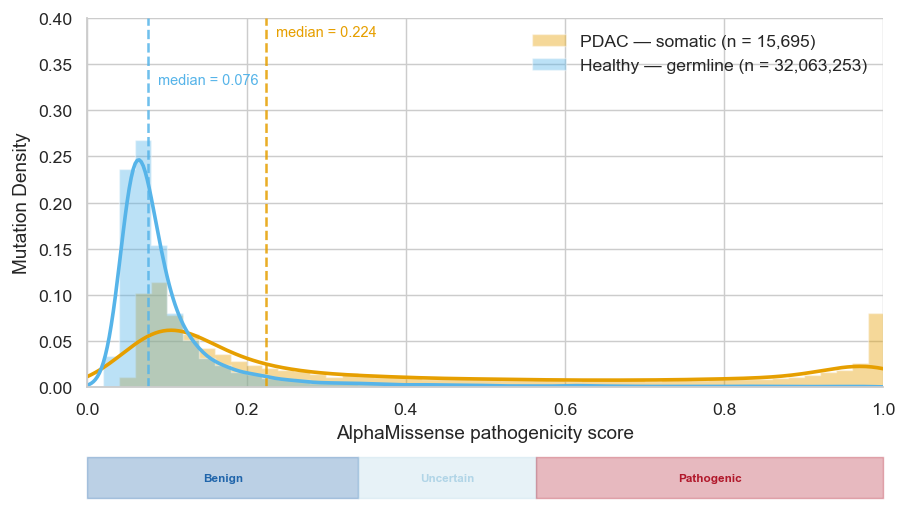

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures


In [23]:
fig, ax = plot_distribution(
    scores_pdac  = tcga['am_pathogenicity'].to_numpy(),
    scores_1000g = g1000['am_pathogenicity'].to_numpy(),
)
fig.savefig(out_dir / 'KO1_am_score_distribution.pdf', dpi=300, bbox_inches='tight')
fig.savefig(out_dir / 'KO1_am_score_distribution.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(out_dir / 'KO1_am_score_distribution.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())

## 5. Figure 2 — Pathogenic Gene Share

Each gene is categorised by the **median** AM score of its mutations within that dataset (gene universes computed independently per dataset).

In [24]:
def categorize_genes(subset):
    # Categorise each gene by the median AM score of its mutations.
    subset = subset.filter(pl.col('am_pathogenicity').is_not_null())
    medians = (
        subset
        .group_by('gene_name')
        .agg(pl.col('am_pathogenicity').median().alias('am_pathogenicity'))
    )
    return _tally(
        medians
        .with_columns(_cat_expr())
        .group_by('category')
        .agg(pl.len().alias('count'))
    )


def plot_stacked_bar(data_dict, title, figsize=(8, 2.8), n_label='mutations'):
    BAR_H = 0.6
    fig, ax = plt.subplots(figsize=figsize)
    labels = list(data_dict.keys())[::-1]   # reversed: PDAC ends up at top
    totals = {lbl: sum(data_dict[lbl].values()) for lbl in labels}

    boundaries = {}   # i -> (right edge of benign, right edge of uncertain)

    for i, label in enumerate(labels):
        c     = data_dict[label]
        total = totals[label]
        if total == 0:
            ax.text(50, i, 'No data', ha='center', va='center', color='grey')
            continue
        pct_b = 100 * c['benign']     / total
        pct_u = 100 * c['uncertain']  / total
        pct_p = 100 * c['pathogenic'] / total

        ax.barh(i, pct_b, left=0,             color=COLOR_BENIGN,    alpha=0.85, height=BAR_H)
        ax.barh(i, pct_u, left=pct_b,         color=COLOR_UNCERTAIN, alpha=0.85, height=BAR_H)
        ax.barh(i, pct_p, left=pct_b + pct_u, color=COLOR_PATH,      alpha=0.85, height=BAR_H)

        boundaries[i] = (pct_b, pct_b + pct_u)

        for left_offset, width, count, cat_color in [
            (0,             pct_b, c['benign'],     COLOR_BENIGN),
            (pct_b,         pct_u, c['uncertain'],  COLOR_UNCERTAIN),
            (pct_b + pct_u, pct_p, c['pathogenic'], COLOR_PATH),
        ]:
            cx = left_offset + width / 2
            if width >= 8:
                ax.text(cx, i, f'{count:,}\n({width:.1f}%)', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold', linespacing=1.25)
            elif width >= 4:
                ax.text(cx, i, f'{width:.1f}%', ha='center', va='center',
                        fontsize=7.5, color='white', fontweight='bold')
            elif width > 0:
                if i == 0:
                    ax.text(cx, i - BAR_H / 2 - 0.06, f'{count:,}\n({width:.1f}%)',
                            ha='center', va='top', fontsize=6.5, color=cat_color,
                            fontweight='bold', linespacing=1.2)
                else:
                    ax.text(cx, i + BAR_H / 2 + 0.06, f'{count:,}\n({width:.1f}%)',
                            ha='center', va='bottom', fontsize=6.5, color=cat_color,
                            fontweight='bold', linespacing=1.2)

    if len(boundaries) == 2:
        y_top_lower = BAR_H / 2
        y_bot_upper = 1 - BAR_H / 2
        all_bounds = [
            (0,                0),
            (boundaries[0][0], boundaries[1][0]),
            (boundaries[0][1], boundaries[1][1]),
            (100,              100),
        ]
        for x0, x1 in all_bounds:
            ax.plot([x0, x1], [y_top_lower, y_bot_upper],
                    color='#555555', lw=0.9, ls=':', zorder=5)

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(
        [f'{lbl}\n(n = {totals[lbl]:,} {n_label})' for lbl in labels]
    )
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.85, len(labels) - 0.3)
    ax.set_title(title, fontsize=11, pad=8, fontweight='semibold')
    ax.xaxis.set_visible(False)
    legend_handles = [
        Patch(facecolor=COLOR_BENIGN,    label='Benign (AM ≤ 0.34)'),
        Patch(facecolor=COLOR_UNCERTAIN, label='Uncertain (0.34 < AM < 0.564)'),
        Patch(facecolor=COLOR_PATH,      label='Pathogenic (AM ≥ 0.564)'),
    ]
    ax.legend(handles=legend_handles, frameon=False, loc='upper center',
              bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8)
    sns.despine(ax=ax, bottom=True, left=True)
    return fig, ax

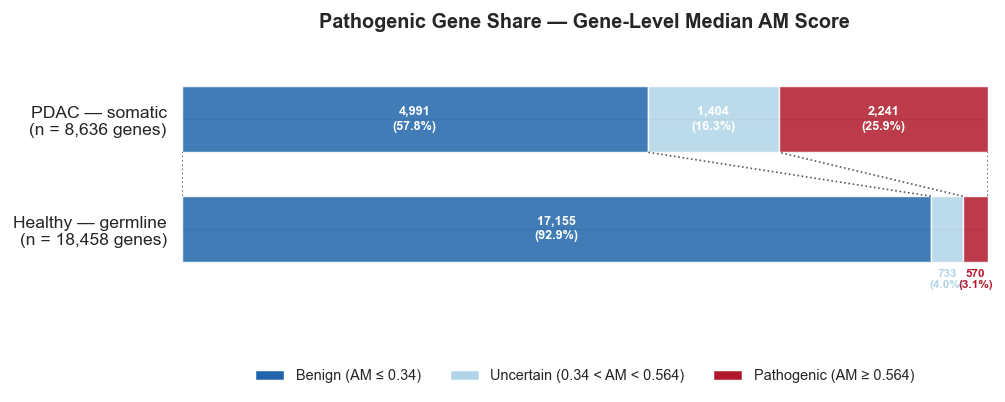

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures


In [25]:
fig, ax = plot_stacked_bar(
    data_dict = {
        'PDAC — somatic':     categorize_genes(tcga),
        'Healthy — germline': categorize_genes(g1000),
    },
    title   = 'Pathogenic Gene Share — Gene-Level Median AM Score',
    n_label = 'genes',
)
fig.savefig(out_dir / 'KO1_pathogenic_gene_share.pdf', dpi=300, bbox_inches='tight')
fig.savefig(out_dir / 'KO1_pathogenic_gene_share.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(out_dir / 'KO1_pathogenic_gene_share.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())